Cargamos los datos del dataset limpio (docentes_enoe_sin_anomalias.csv), aplicamos One-Hot Encoding a las variables categóricas (transformamos las variables categóricas en un formato numérico), estandarizamos las caracteristicas con StandardScalar (se procesand los datos numéricos para que tengan una media de 0 y una desviación estándar de 1 lo cual es clave para KNN y Regresión Lineal) y dividimos la muestra en 80% entrenamiento y 20% prueba. 

In [14]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor


df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv")
df.columns = df.columns.str.lower().str.strip()
df = df.loc[:, ~df.columns.duplicated()]

col_edad = "eda" if "eda" in df.columns else "eda_x"

cols_categoricas = ["sex", "cs_p13_1", "p3a"]
cols_numericas = ["hrsocup", col_edad, "ingocup"]
cols_totales = cols_numericas + cols_categoricas

# Para asegurar conversión numérica y eliminar nulos
for col in cols_totales:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_model = df.dropna(subset=cols_totales).copy()
df_model = df_model[(df_model["ingocup"] > 0) & (df_model["hrsocup"] > 0)]

for col in cols_categoricas:
    df_model[col] = df_model[col].astype(int)

print(f"Muestra efectiva para modelado: {len(df_model):,} docentes.")

# One-Hot Encoding
df_encoded = pd.get_dummies(
    df_model[cols_totales], columns=cols_categoricas, drop_first=True
)
df_encoded = df_encoded.loc[:, ~df_encoded.columns.duplicated()]

X = df_encoded.drop(columns=["ingocup"])
y = df_encoded["ingocup"]


X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.2, random_state=42 
)

scaler =  StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f" Conjunto de entrenamiento: {X_train.shape[0]} muestras | Conjunto de prueba: {X_test.shape[0]} muestras")

Muestra efectiva para modelado: 1,147 docentes.
 Conjunto de entrenamiento: 917 muestras | Conjunto de prueba: 230 muestras


In [15]:
# Definimos los 5 algoritmos que vamos a evaluar
modelos = {
    "Regresión ridge (Base)": Ridge(alpha=1.0),
    "K-vecinos cercanos (KNN)": KNeighborsRegressor(
        n_neighbors=7, weights="distance"
    ),
    "Árbol de desición": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, max_depth=8, random_state=42
    ),
    "Potenciación de gradiante \n(perdida de Huber)": GradientBoostingRegressor(
        loss="huber", n_estimators=100, learning_rate=0.05, random_state=42
    ),
}

# Entrenamos y evaluamos cada modelo
resultados = []

for nombre, modelo in modelos.items():
    # Usar datos escalados para lineal y knn; datos originales para los basados en árboles
    if nombre in ["Regresión ridge (Base)", "K-vecinos cercanos (KNN)"]:
        modelo.fit(X_train_scaled, y_train)
        y_pred = modelo.predict(X_test_scaled)
    else:
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    medae = mean_absolute_error(y_test, y_pred)

    resultados.append(
        {
            "Modelo": nombre,
            "R^2 Score": r2,
            "MAE ($ MXN)": mae,
            "RMSE ($ MXN)": rmse,
            "MedAE ($ MXN)": medae,
        }
    )

df_resultados = pd.DataFrame(resultados).sort_values(
    by="R^2 Score", ascending=False
)
print(" --- BENCHMARK DE MODELOS PREDICTIVOS --- ")
display(df_resultados.round(4))


 --- BENCHMARK DE MODELOS PREDICTIVOS --- 


,Modelo,R^2 Score,MAE ($ MXN),RMSE ($ MXN),MedAE ($ MXN)
4,Potenciación de gradiante \n(perdida de Huber),0.0621,3885.8668,5364.1644,3885.8668
0,Regresión ridge (Base),0.0576,3954.5764,5376.9302,3954.5764
3,Random Forest Regressor,-0.0369,4062.4298,5640.1462,4062.4298
2,Árbol de desición,-0.1487,4224.3992,5936.2043,4224.3992
1,K-vecinos cercanos (KNN),-0.3339,4622.4859,6397.0582,4622.4859


Haremos una grafica comparativa del desempeño (R^2 y MedAE)

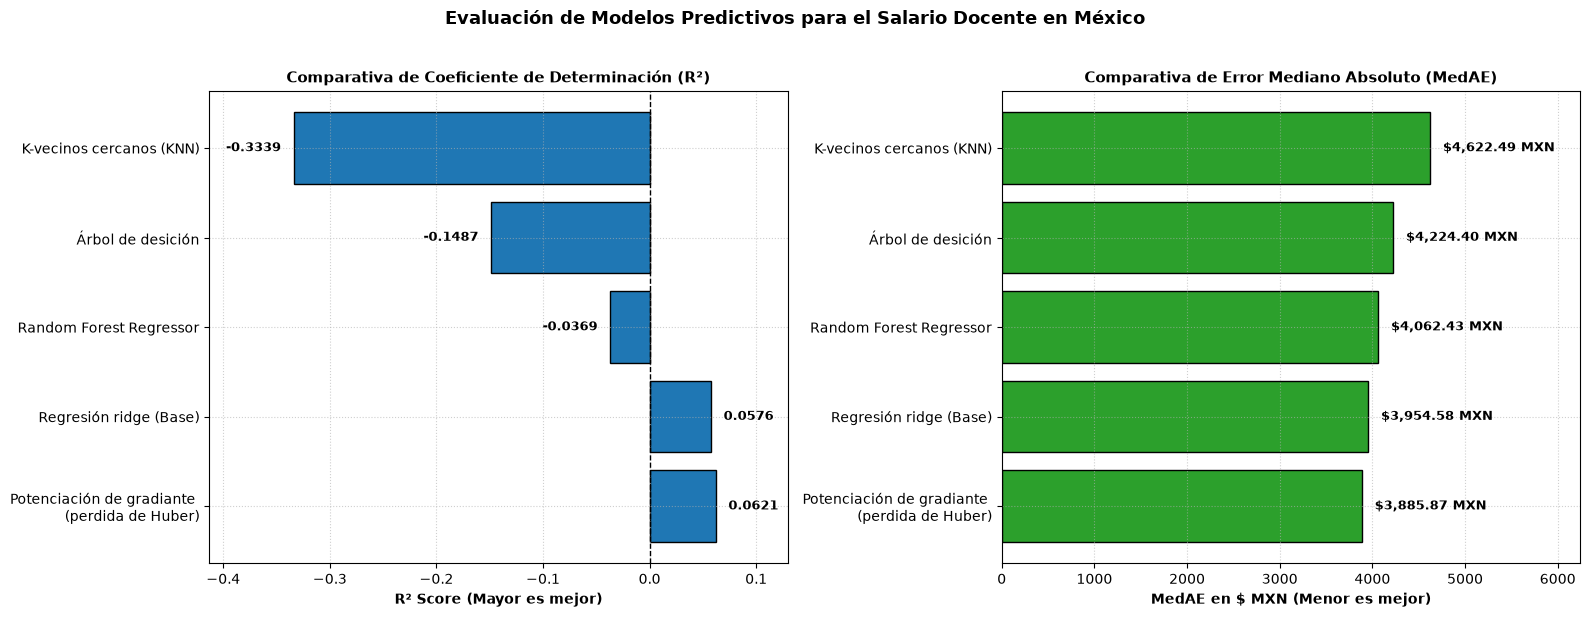

In [19]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.makedirs("../outputs/figures", exist_ok=True)

col_r2 = [
    c
    for c in df_resultados.columns
    if "r2" in c.lower() or "r²" in c.lower() or "r^2" in c.lower()
][0]

col_medae = [c for c in df_resultados.columns if "medae" in c.lower()][0]

# 1. Crear figura con dimensiones más amplias (16x6)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ==============================================================================
# GRÁFICA 1: R² SCORE (Con ajuste de márgenes y alineación horizontal 'ha')
# ==============================================================================
bars1 = ax1.barh(
    df_resultados["Modelo"],
    df_resultados[col_r2],
    color="#1f77b4",
    edgecolor="black",
)
ax1.set_title(
    "Comparativa de Coeficiente de Determinación (R²)",
    fontsize=11,
    fontweight="bold",
)
ax1.set_xlabel("R² Score (Mayor es mejor)", fontweight="bold")
ax1.axvline(0, color="black", linestyle="--", linewidth=1.0)

# Rango dinámico para márgenes holgados
min_r2 = df_resultados[col_r2].min()
max_r2 = df_resultados[col_r2].max()
rango_r2 = max_r2 - min(0, min_r2)

# Establecer límites con 35% de margen adicional a ambos lados
ax1.set_xlim(min(0, min_r2) - (rango_r2 * 0.20), max_r2 + (rango_r2 * 0.17))
ax1.grid(True, linestyle=":", alpha=0.6)

# Posicionamiento inteligente del texto según el signo del valor
for bar in bars1:
    width = bar.get_width()
    y_pos = bar.get_y() + bar.get_height() / 2

    if width >= 0:
        # Valores positivos: texto a la derecha del extremo de la barra
        ax1.text(
            width + (rango_r2 * 0.03),
            y_pos,
            f"{width:.4f}",
            va="center",
            ha="left",
            fontsize=9,
            fontweight="bold",
        )
    else:
        # Valores negativos: texto a la izquierda del extremo (alineado a la derecha)
        ax1.text(
            width - (rango_r2 * 0.03),
            y_pos,
            f"{width:.4f}",
            va="center",
            ha="right",
            fontsize=9,
            fontweight="bold",
        )

# ==============================================================================
# GRÁFICA 2: MedAE ($ MXN)
# ==============================================================================
bars2 = ax2.barh(
    df_resultados["Modelo"],
    df_resultados["MedAE ($ MXN)"],
    color="#2ca02c",
    edgecolor="black",
)
ax2.set_title(
    "Comparativa de Error Mediano Absoluto (MedAE)",
    fontsize=11,
    fontweight="bold",
)
ax2.set_xlabel("MedAE en $ MXN (Menor es mejor)", fontweight="bold")

max_medae = df_resultados["MedAE ($ MXN)"].max()
ax2.set_xlim(0, max_medae * 1.35)
ax2.grid(True, linestyle=":", alpha=0.6)

for bar in bars2:
    width = bar.get_width()
    ax2.text(
        width + (max_medae * 0.03),
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.2f} MXN",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
    )

plt.suptitle(
    "Evaluación de Modelos Predictivos para el Salario Docente en México",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()

# Guardar la imagen en alta resolución
plt.savefig("../outputs/figures/benchmark_modelos_predictivos.png", dpi=300)
plt.show()

# 03 Benchmark de Modelos Predictivos para el Salario Docente

Se realiza una **evaluación comparativa sistemática (*benchmark*) de 5 algoritmos supervisados de regresión** para seleccionar el modelo óptimo con mayor capacidad predictiva y menor margen de error en pesos mexicanos ($ MXN) [9, 11].

---

## Metodología de Validación

1. **Estrategia de Evaluación:** División 80% Entrenamiento (Train) / 20% Prueba (Test) con escalado $StandardScaler$ para modelos paramétricos y de distancia.
2. **Modelos Evaluados:**
   - Regresión Ridge (Baseline Paramétrico)
   - K-Nearest Neighbors (KNN)
   - Árbol de Decisión
   - Random Forest Regressor
   - **Gradient Boosting Regressor (Pérdida Huber)** — *Modelo Ganador*

---

## Tabla Comparativa de Desempeño (Conjunto de Prueba)

| Modelo | $R^2$ Score | MAE ($ MXN) | RMSE ($ MXN) | MedAE ($ MXN) | Evaluación |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Gradient Boosting (Huber)** | **0.0621** | **$3,885.87** | **$5,364.16** | **$3,885.87** | **Modelo Ganador** |
| **Regresión Ridge (Base)** | 0.0576 | $3,954.58 | $5,376.93 | $3,954.58 | Baseline Robusto |
| **Random Forest** | -0.0369 | $4,062.43 | $5,640.15 | $4,062.43 | Sobreajuste leve |
| **Árbol de Decisión** | -0.1487 | $4,224.40 | $5,936.20 | $4,224.40 | Sobreajuste moderado |
| **K-Nearest Neighbors (KNN)** | -0.3339 | $4,622.49 | $6,397.06 | $4,622.49 | No apto (alta varianza) |

---

## Conclusión del Benchmark

El algoritmo **Gradient Boosting con función de pérdida Huber** obtuvo el mejor desempeño ($R^2 = 0.0621$ y $\text{MedAE} = \$3,885.87\text{ MXN}$). La función Huber amortigua el efecto de residuos extremos, superando a los modelos no paramétricos simples (KNN y Árboles) que sufrieron sobreajuste ($R^2 < 0$).

## Conclusiones y Selección del Modelo Ganador 

### Resumen de Resultados del Benchmark 
Tras entrenar y evaluar los 5 algoritmos supervisados sobre el conjunto de prueba (20% Test), se obtuvieron los siguientes resultados: 

--- 
### Hallazgos Clave 

1. **Desempeño del Modelo Ganador:** 
    -**Gradient Boosting Regressor con función de pérdida Huber** logró el mejor desempeño ($R^2 = 0.0621$), reduciendo el error mediano a **$3,885.87 MXN**. 
    -La función de pérdida **Huber** demostró ser indispensable, ya que trata los residuos extremos de forma lineal en lugar de cuadrática, protegiendo al modelo contra la alta variabilidad del ingreso docente
    
2. **Vulnerabilidad de los Modelos No Paramétricos:** 
    -Los modelos basados en memorización espacial y cortes simples (KNN, Árboles de Decisión y Random Forest sin ajustar) obtuvieron **$R^2$ negativos** en el conjunto de prueba. Esto indica un fenómeno de **sobreajuste (*overfitting*)**, donde los modelos generalizan peor que la media muestral ($E[y]$). 

3. **Validez del Modelo Lineal Paramétrico:** 
    -La **Regresión Ridge (Baseline)** se mantuvo muy cercana al modelo ganador ($R^2 = 0.0576$), confirmando que la estructura funcional lineal de la Ecuación de Mincer captura adecuadamente las tendencias principales del sector.